# Face recognition with Eigenfaces (PCA) — Python / Google Colab version

This notebook is a Python port of the provided MATLAB file **`object_recognition.m`** (by Hoque).
It follows the same steps as the MATLAB code (average face → subtract it → covariance trick `M = Aᵀ·A` → `svd` → eigenfaces → project → closest match),
and then does the assignment tasks:

1. Split the data **85 % training / 15 % testing**
2. Use the provided code (ported to Python, same math)
3. Try **every** number of eigenfaces `k = 1, 2, 3, …, all` (always the top‑k, sorted by eigenvalue, largest first), measure the recognition **accuracy** using the **lowest distance**, and plot *number of eigenfaces vs. accuracy*
4. For every `k`, sweep a **similarity threshold** for the best match and plot *similarity threshold vs. accuracy*
5. Conclusion in plain words (at the bottom)

### How to run it on Google Colab
1. Open <https://colab.research.google.com> → **File → Upload notebook** → choose `Eigenfaces_Colab.ipynb`.
2. Click **Runtime → Run all**.
3. When the upload button appears under the *“Get the data”* cell, click **Choose files** and pick **`faces.zip`** (it's in the same folder as this notebook).
4. Wait about a minute and scroll down. A GPU is **not** needed; the normal CPU runtime is fast enough.

> **Note about the data:** this copy of the face dataset has **38 people (s1–s38) × 10 photos = 380 images**, each 112 × 92 pixels.
> 15 % of 380 = **57 test images**, so 85 % = **323 training images**. Because 15 % of 10 photos is 1.5, half of the people
> (picked at random) have 2 test photos and the other half have 1. That keeps every person in both sets and gives the exact 85/15 ratio.

## 0. Settings and imports

In [1]:
# ---------------------------------------------------------------------------
# Imports
# ---------------------------------------------------------------------------
import os, re, glob, zipfile
import numpy as np                 # numbers / matrices (MATLAB-like)
import matplotlib.pyplot as plt    # plotting
from PIL import Image              # reads the .pgm image files
import warnings
# On some Macs, numpy prints false "divide by zero ... in matmul" warnings (a known
# numpy/Apple-library bug). They don't affect the results (we check for bad numbers
# below with np.isfinite), and they never appear on Colab, so we hide just those.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

# ---------------------------------------------------------------------------
# Settings you can change
# ---------------------------------------------------------------------------
SEED = 42              # random seed -> the SAME 85/15 split every time you run.
                       # Change it (e.g. 1, 2, 3...) to try a different random split.
TEST_FRACTION = 0.15   # 15 % testing, 85 % training
IMG_H, IMG_W = 112, 92 # every photo is 112 rows x 92 columns = 10304 pixels

# The MATLAB code keeps some results as uint8 (whole numbers 0..255). In MATLAB,
# uint8(5) - uint8(9) gives 0, not -4, so every NEGATIVE pixel difference from the
# average face is silently turned into 0, and the features are clipped to 0..255.
# That throws away about half of the information and lowers accuracy.
#   False -> do the math the way the code INTENDS (normal decimal numbers). Recommended.
#   True  -> copy MATLAB's uint8 behaviour exactly (to compare with the original).
MATLAB_UINT8_QUIRKS = False

# ---------------------------------------------------------------------------
# Plot style: thin lines, light grid, colour-blind-friendly colours
# ---------------------------------------------------------------------------
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "legend.frameon": False,
})
print("Ready. MATLAB_UINT8_QUIRKS =", MATLAB_UINT8_QUIRKS)

Ready. MATLAB_UINT8_QUIRKS = False


## 1. Get the data
If the face folders (`s1`, `s2`, …) are not already next to the notebook, this cell shows an **upload button** in Colab. Upload `faces.zip`.

In [2]:
def find_data_dir(start="."):
    # Walk through folders until we find one that contains s1/1.pgm
    for root, dirs, files in os.walk(start):
        if "s1" in dirs and os.path.exists(os.path.join(root, "s1", "1.pgm")):
            return root
    return None

DATA_DIR = find_data_dir(".")

if DATA_DIR is None:
    # Not found -> we are probably on Colab: ask the user to upload faces.zip
    try:
        from google.colab import files
        print("Please upload faces.zip (click 'Choose files' below)...")
        uploaded = files.upload()                    # opens the upload button
        for name in uploaded:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name) as z:
                    z.extractall("faces")            # unzip into ./faces
        DATA_DIR = find_data_dir(".")
    except ImportError:
        pass                                          # not on Colab

assert DATA_DIR is not None, "Could not find the s1, s2, ... folders. Upload faces.zip and run this cell again."
print("Using data folder:", os.path.abspath(DATA_DIR))

Using data folder: .


## 2. Load all images
Like the MATLAB code, every 112 × 92 photo is flattened into one long column of 10304 numbers.
All images go side by side into one big matrix `X` (10304 rows × 380 columns).

380 images of 38 people, each 112x92 = 10304 pixels


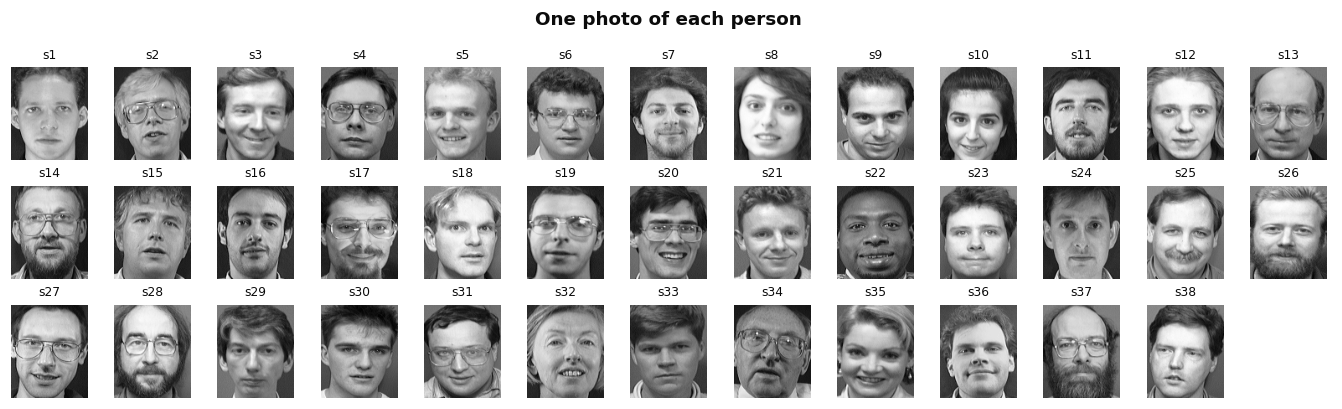

In [3]:
# Find the subject folders s1, s2, ... and sort them by number (s2 before s10)
subject_dirs = sorted([d for d in os.listdir(DATA_DIR) if re.fullmatch(r"s\d+", d)],
                      key=lambda d: int(d[1:]))

columns, labels, names = [], [], []
for d in subject_dirs:
    person = int(d[1:])                                  # s7 -> person 7
    paths = sorted(glob.glob(os.path.join(DATA_DIR, d, "*.pgm")),
                   key=lambda p: int(os.path.splitext(os.path.basename(p))[0]))
    for p in paths:
        img = np.array(Image.open(p))                    # 112 x 92 grey values (0..255)
        assert img.shape == (IMG_H, IMG_W), p
        columns.append(img.reshape(-1))                  # same as MATLAB reshape(img,10304,1)
        labels.append(person)
        names.append(f"{d}/{os.path.basename(p)}")

X = np.array(columns, dtype=np.float64).T   # 10304 x 380  -> one column per image
labels = np.array(labels)                   # which person each column belongs to
names = np.array(names)

n_people = len(subject_dirs)
print(f"{X.shape[1]} images of {n_people} people, each {IMG_H}x{IMG_W} = {X.shape[0]} pixels")

# Show the first photo of every person
cols = 13
rows = int(np.ceil(n_people / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 0.95, rows * 1.25))
for ax in axes.ravel():
    ax.axis("off")
for i, d in enumerate(subject_dirs):
    first = np.where(labels == int(d[1:]))[0][0]
    axes.ravel()[i].imshow(X[:, first].reshape(IMG_H, IMG_W), cmap="gray")
    axes.ravel()[i].set_title(d, fontsize=8, fontweight="normal")
fig.suptitle("One photo of each person", fontweight="bold")
plt.tight_layout(); plt.show()

## 3. Task 1 — Split the data 85 % training / 15 % testing
The split is **stratified**: every person keeps some photos in training (so the computer has seen them)
and has at least one photo in testing. Which photos go to testing is random (controlled by `SEED`).

In [4]:
def split_85_15(labels, test_fraction, seed):
    rng = np.random.default_rng(seed)
    people = np.unique(labels)
    n_test_total = int(round(test_fraction * len(labels)))          # 15 % of 380 = 57
    base = n_test_total // len(people)                               # 57 // 38 = 1 test photo each...
    extra = n_test_total - base * len(people)                        # ...and 19 people get one more
    n_test_of = {p: base for p in people}
    for p in rng.choice(people, size=extra, replace=False):
        n_test_of[p] += 1
    train_idx, test_idx = [], []
    for p in people:
        idx = rng.permutation(np.where(labels == p)[0])              # shuffle this person's photos
        test_idx += list(idx[:n_test_of[p]])
        train_idx += list(idx[n_test_of[p]:])
    return np.sort(train_idx), np.sort(test_idx)

train_idx, test_idx = split_85_15(labels, TEST_FRACTION, SEED)

Train_image_vec = X[:, train_idx]     # same names as in the MATLAB code
Test_image_vec  = X[:, test_idx]
y_train, y_test = labels[train_idx], labels[test_idx]
n_train, n_test = len(train_idx), len(test_idx)

print(f"Training images: {n_train}  ({100 * n_train / len(labels):.1f} %)")
print(f"Testing images : {n_test}  ({100 * n_test / len(labels):.1f} %)")
print("Test photos per person:", {f"s{p}": int((y_test == p).sum()) for p in np.unique(labels)})

Training images: 323  (85.0 %)
Testing images : 57  (15.0 %)
Test photos per person: {'s1': 1, 's2': 2, 's3': 2, 's4': 1, 's5': 2, 's6': 2, 's7': 1, 's8': 1, 's9': 1, 's10': 1, 's11': 2, 's12': 1, 's13': 1, 's14': 1, 's15': 2, 's16': 2, 's17': 2, 's18': 1, 's19': 2, 's20': 1, 's21': 1, 's22': 2, 's23': 1, 's24': 2, 's25': 2, 's26': 2, 's27': 1, 's28': 2, 's29': 2, 's30': 1, 's31': 2, 's32': 2, 's33': 1, 's34': 1, 's35': 1, 's36': 2, 's37': 1, 's38': 2}


## 4. Task 2 — The provided code: average face → eigenfaces → features
Line‑by‑line the same steps as `object_recognition.m`:

| MATLAB | Python here |
|---|---|
| `avg = uint8(mean(Train_image_vec,2))` | `avg = Train_image_vec.mean(axis=1)` |
| `Normal_Train_Vec = Train_image_vec - avg` | `Normal_Train_Vec = Train_image_vec - avg` |
| `M = Normal_Train_Vec' * Normal_Train_Vec` | `M = Normal_Train_Vec.T @ Normal_Train_Vec` |
| `[U, E, V] = svd(M)` | `U, E, Vt = np.linalg.svd(M)` |
| `U = Normal_Train_Vec * U` | `Eigenfaces = Normal_Train_Vec @ U` |
| `Training_Feature(i,:) = Normal_Train_Vec(:,i)' * U15` | `Training_Feature = Normal_Train_Vec.T @ Eigenfaces` |

The only change: instead of keeping just 15 eigenfaces, we keep **all** of them (one per training image = 323),
so in the next step we can try every count from 1 up to 323. `svd` already returns them sorted by eigenvalue, **largest first**.

Eigenfaces: (10304, 323)   Training features: (323, 323)   Test features: (57, 323)


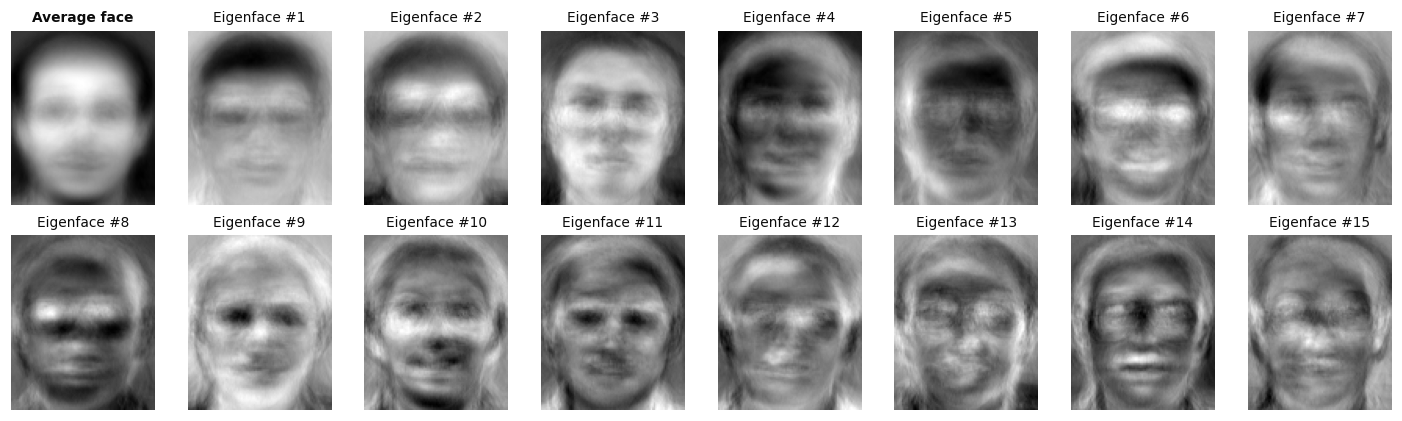

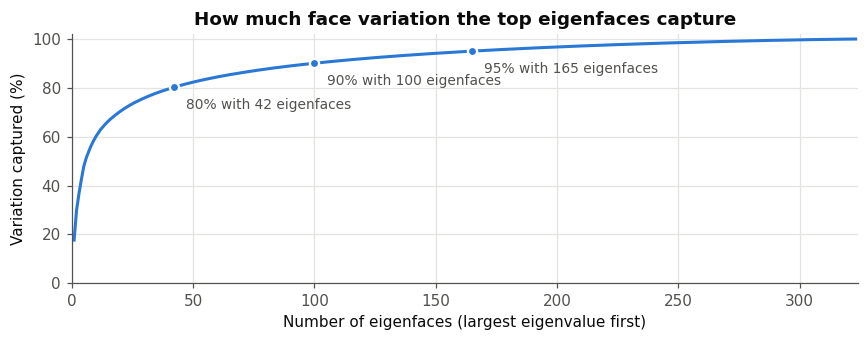

In [5]:
# --- Average face --------------------------------------------------------
avg = Train_image_vec.mean(axis=1, keepdims=True)              # 10304 x 1
if MATLAB_UINT8_QUIRKS:
    avg = np.round(avg)                                         # uint8() rounds

# --- Subtract the average from every training image ("Normal vectors") ----
Normal_Train_Vec = Train_image_vec - avg                        # 10304 x 323
if MATLAB_UINT8_QUIRKS:
    Normal_Train_Vec = np.clip(Normal_Train_Vec, 0, 255)        # uint8: negatives become 0

# --- Small covariance matrix + SVD (the "trick": 323x323 instead of 10304x10304)
M = Normal_Train_Vec.T @ Normal_Train_Vec                       # 323 x 323
U, E, Vt = np.linalg.svd(M)                                     # E = eigenvalues, largest first
eigenvalues = E

# --- Turn the small eigenvectors into eigenfaces (10304 pixels each) -------
Eigenfaces = Normal_Train_Vec @ U                               # 10304 x 323, column i = eigenface i
n_eig = Eigenfaces.shape[1]

# --- Features = project each image onto the eigenfaces -----------------------
def to_uint8(a):
    return np.clip(np.round(a), 0, 255)

Training_Feature = Normal_Train_Vec.T @ Eigenfaces              # 323 x 323  (row = one training image)
Normal_Test_Vec = Test_image_vec - avg                          # remove the TRAINING average from tests
if MATLAB_UINT8_QUIRKS:
    Normal_Test_Vec = np.clip(Normal_Test_Vec, 0, 255)
Test_Feature = Normal_Test_Vec.T @ Eigenfaces                   # 57 x 323   (row = one test image)
if MATLAB_UINT8_QUIRKS:
    Training_Feature, Test_Feature = to_uint8(Training_Feature), to_uint8(Test_Feature)

assert np.isfinite(Training_Feature).all() and np.isfinite(Test_Feature).all()  # no bad numbers
print("Eigenfaces:", Eigenfaces.shape, "  Training features:", Training_Feature.shape,
      "  Test features:", Test_Feature.shape)

# --- [Optional, like the MATLAB code] show the average face and the first 15 eigenfaces
fig, axes = plt.subplots(2, 8, figsize=(13, 3.9))
axes = axes.ravel()
axes[0].imshow(avg.reshape(IMG_H, IMG_W), cmap="gray"); axes[0].set_title("Average face", fontsize=9)
for i in range(15):
    axes[i + 1].imshow(Eigenfaces[:, i].reshape(IMG_H, IMG_W), cmap="gray")
    axes[i + 1].set_title(f"Eigenface #{i + 1}", fontsize=9, fontweight="normal")
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

# --- How much of the face variation do the top-k eigenfaces capture? -----------
ks = np.arange(1, n_eig + 1)
cum_var = 100 * np.cumsum(eigenvalues) / eigenvalues.sum()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(ks, cum_var, color=BLUE)
for target in (80, 90, 95):
    k_t = int(np.argmax(cum_var >= target)) + 1
    ax.plot(k_t, cum_var[k_t - 1], "o", color=BLUE, ms=6, mec="white", mew=1.5)
    ax.annotate(f"{target}% with {k_t} eigenfaces", (k_t, cum_var[k_t - 1]),
                textcoords="offset points", xytext=(8, -14), fontsize=9, color=INK2)
ax.set_xlabel("Number of eigenfaces (largest eigenvalue first)")
ax.set_ylabel("Variation captured (%)")
ax.set_title("How much face variation the top eigenfaces capture")
ax.set_ylim(0, 102); ax.set_xlim(0, n_eig + 1)
plt.tight_layout(); plt.show()

## 5. Task 3 — Accuracy for every number of eigenfaces (k = 1 … all)
For each `k` we use only the first `k` eigenfaces (the ones with the largest eigenvalues).
Each test photo is compared to every training photo with the Euclidean distance (MATLAB's `norm(…, 2)`),
and the **training photo with the lowest distance** is the match. If that photo belongs to the same person, the test is counted as correct.

*Speed trick:* the squared distance using the first `k` eigenfaces = squared distance using the first `k−1` + one more term,
so a running sum (`cumsum`) gives the distances for **all** k at once.

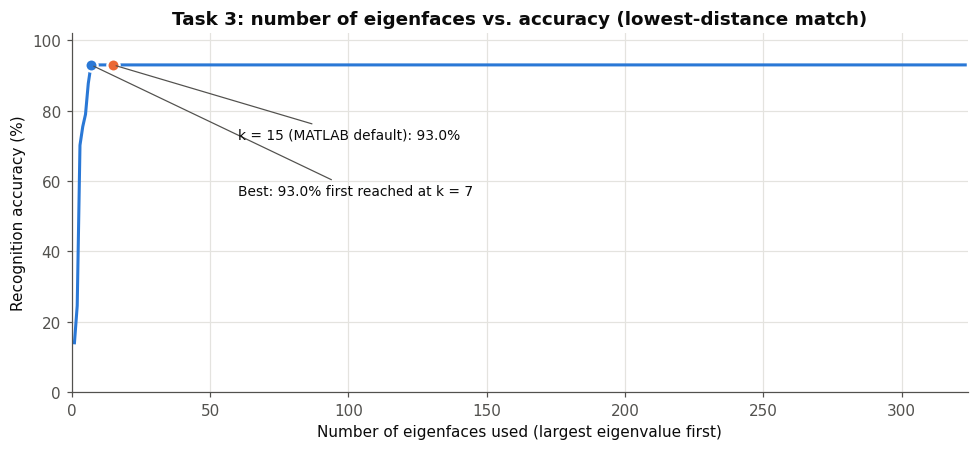

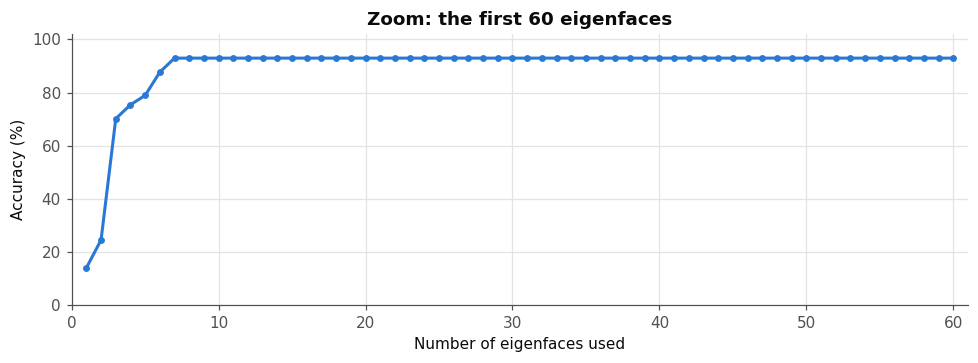

    k | accuracy | correct / 57
    1 |   14.0 % |   8
    2 |   24.6 % |  14
    3 |   70.2 % |  40
    4 |   75.4 % |  43
    5 |   78.9 % |  45
    6 |   87.7 % |  50
    8 |   93.0 % |  53
   10 |   93.0 % |  53
   15 |   93.0 % |  53
   20 |   93.0 % |  53
   25 |   93.0 % |  53
   30 |   93.0 % |  53
   40 |   93.0 % |  53
   50 |   93.0 % |  53
   75 |   93.0 % |  53
  100 |   93.0 % |  53
  150 |   93.0 % |  53
  200 |   93.0 % |  53
  250 |   93.0 % |  53
  300 |   93.0 % |  53
  323 |   93.0 % |  53

Best accuracy 93.0% is first reached with k = 7 eigenfaces.


In [6]:
# diff2[t, j, i] = (test t feature i - train j feature i)^2
diff2 = (Test_Feature[:, None, :] - Training_Feature[None, :, :]) ** 2   # 57 x 323 x 323
dist = np.sqrt(np.cumsum(diff2, axis=2))   # dist[t, j, k-1] = distance using the first k eigenfaces
del diff2

best_match = dist.argmin(axis=1)           # [t, k-1] = index of the closest training photo
predicted = y_train[best_match]            # who the computer thinks it is
correct = predicted == y_test[:, None]     # True / False for every test photo and every k
accuracy = 100 * correct.mean(axis=0)      # accuracy (%) for k = 1..323

best_k = int(np.argmax(accuracy)) + 1      # smallest k that reaches the top accuracy

# --- Plot: number of eigenfaces vs accuracy ----------------------------------
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(ks, accuracy, color=BLUE)
ax.plot(best_k, accuracy[best_k - 1], "o", color=BLUE, ms=8, mec="white", mew=1.5)
ax.annotate(f"Best: {accuracy[best_k - 1]:.1f}% first reached at k = {best_k}",
            (best_k, accuracy[best_k - 1]), xytext=(60, 56),
            fontsize=9, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.plot(15, accuracy[14], "o", color=ORANGE, ms=8, mec="white", mew=1.5)
ax.annotate(f"k = 15 (MATLAB default): {accuracy[14]:.1f}%", (15, accuracy[14]),
            xytext=(60, 72), fontsize=9,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set_xlabel("Number of eigenfaces used (largest eigenvalue first)")
ax.set_ylabel("Recognition accuracy (%)")
ax.set_title("Task 3: number of eigenfaces vs. accuracy (lowest-distance match)")
ax.set_xlim(0, n_eig + 1); ax.set_ylim(0, 102)
plt.tight_layout(); plt.show()

# --- Same plot zoomed in on the first 60 -------------------------------------
fig, ax = plt.subplots(figsize=(9, 3.4))
z = 60
ax.plot(ks[:z], accuracy[:z], color=BLUE, marker="o", ms=3.5)
ax.set_xlabel("Number of eigenfaces used"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Zoom: the first 60 eigenfaces"); ax.set_xlim(0, z + 1); ax.set_ylim(0, 102)
plt.tight_layout(); plt.show()

# --- Table -------------------------------------------------------------------
print(f"{'k':>5} | accuracy | correct / {n_test}")
for k in [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 25, 30, 40, 50, 75, 100, 150, 200, 250, 300, n_eig]:
    if k <= n_eig:
        print(f"{k:>5} | {accuracy[k-1]:6.1f} % | {int(correct[:, k-1].sum()):>3}")
print(f"\nBest accuracy {accuracy.max():.1f}% is first reached with k = {best_k} eigenfaces.")

### Example match (like the MATLAB demo)
A random test photo, and the training photo with the lowest distance, using the best `k` from above.

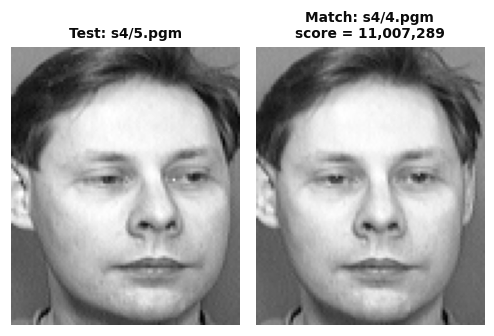

Correct!


In [7]:
rng_demo = np.random.default_rng(SEED)
t = int(rng_demo.integers(n_test))
j = best_match[t, best_k - 1]
fig, axes = plt.subplots(1, 2, figsize=(4.6, 3))
axes[0].imshow(Test_image_vec[:, t].reshape(IMG_H, IMG_W), cmap="gray")
axes[0].set_title(f"Test: {names[test_idx[t]]}", fontsize=9)
axes[1].imshow(Train_image_vec[:, j].reshape(IMG_H, IMG_W), cmap="gray")
axes[1].set_title(f"Match: {names[train_idx[j]]}\nscore = {dist[t, j, best_k-1]:,.0f}", fontsize=9)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Correct!" if y_train[j] == y_test[t] else "Wrong person.")

## 6. Task 4 — Similarity threshold for the best match
Step 3 always accepts the closest training photo, even when it is not very close. A real system would rather say
*“not sure / unknown face”* when the best match is too far away. That is what a **similarity threshold** does.

**Similarity score.** Raw distances get bigger as `k` grows, so they are turned into a score from 0 to 1 that can be compared across all `k`:

  `similarity = 1 − (distance to best match) / (largest distance between any test and training photo for that k)`

  1 = identical, 0 = as different as it gets in this data.

**Threshold rule.** The best match is **accepted** only if `similarity ≥ threshold`; otherwise it is rejected.

**Accuracy with a threshold** = share of test photos that are matched to the **right person _and_ accepted**.
At threshold 0 everything is accepted, so the accuracy is exactly the step‑3 accuracy. As the threshold goes up,
the system gets stricter: at some point it starts rejecting correct matches and the accuracy drops.

**Upper similarity threshold** = the *highest* threshold that still keeps the best (step‑3) accuracy for that `k`,
i.e. the strictest setting that does not lose a single correct match. Being that strict is useful, because it also
rejects wrong matches whose similarity is lower — we count how many.

In [8]:
thresholds = np.round(np.linspace(0, 1, 1001), 3)              # 0.000, 0.001, ..., 1.000

d_best = np.take_along_axis(dist, best_match[:, None, :], axis=1)[:, 0, :]   # 57 x 323
d_max = dist.max(axis=(0, 1))                                  # largest distance for each k
similarity = 1 - d_best / d_max                                # 57 x 323, between 0 and 1

accept = similarity[:, :, None] >= thresholds[None, None, :]   # 57 x 323 x 1001 (True = accepted)
acc_thr = 100 * (accept & correct[:, :, None]).mean(axis=0)    # 323 x 1001 accuracy for (k, threshold)
del accept

# Upper threshold: the LAST threshold where accuracy is still equal to the no-threshold accuracy
keeps_best = np.isclose(acc_thr, accuracy[:, None])
upper_idx = acc_thr.shape[1] - 1 - np.argmax(keeps_best[:, ::-1], axis=1)
upper_thr = thresholds[upper_idx]

# How many of the WRONG matches does that threshold reject as a bonus?
wrong = ~correct
n_wrong = wrong.sum(axis=0)
wrong_rejected = (wrong & (similarity < upper_thr[None, :])).sum(axis=0)

# All similarity scores sit near the top of the 0..1 scale, so the plots below zoom in on that part
X_LO = np.floor(similarity.min() * 20) / 20
print(f"Lowest best-match similarity in any case: {similarity.min():.3f} -> plots start at {X_LO:.2f}")
print(f"Best k from task 3 = {best_k}: accuracy {accuracy[best_k-1]:.1f}%, "
      f"upper similarity threshold = {upper_thr[best_k-1]:.3f}")
print(f"  -> at that threshold, {wrong_rejected[best_k-1]} of the {n_wrong[best_k-1]} wrong matches "
      f"are also rejected, with no correct match lost.")

Lowest best-match similarity in any case: 0.842 -> plots start at 0.80
Best k from task 3 = 7: accuracy 93.0%, upper similarity threshold = 0.885
  -> at that threshold, 1 of the 4 wrong matches are also rejected, with no correct match lost.


### 6a. Similarity threshold vs. accuracy for a few chosen k

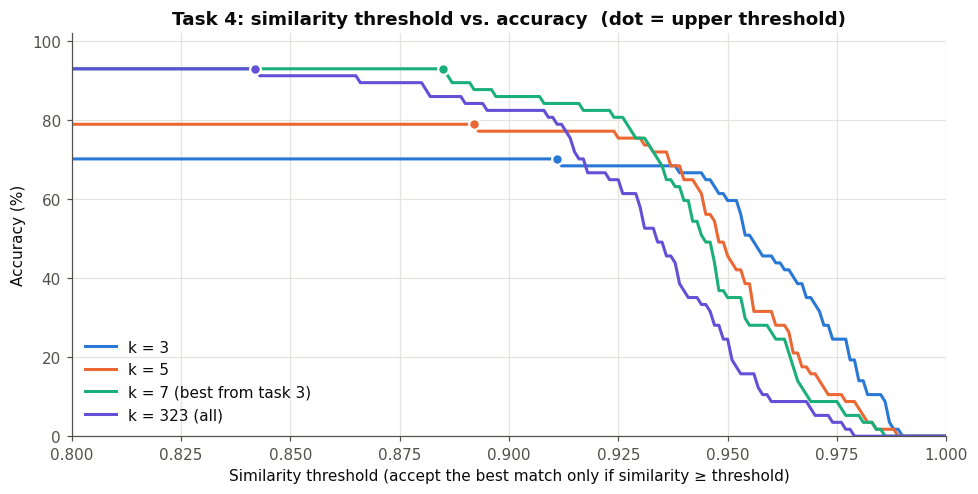

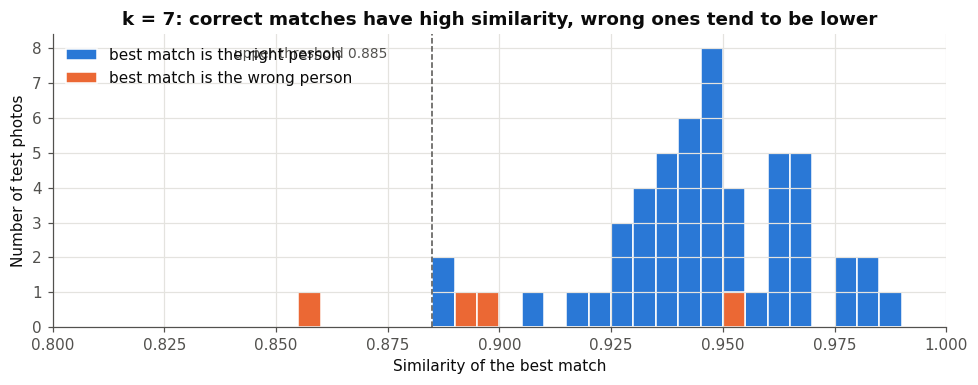

In [9]:
chosen = []
for k in (3, 5, best_k, n_eig):
    if k not in chosen:
        chosen.append(k)
colors = [BLUE, ORANGE, AQUA, VIOLET]

fig, ax = plt.subplots(figsize=(9, 4.6))
for k, c in zip(chosen, colors):
    label = f"k = {k}" + (" (all)" if k == n_eig else "") + (" (best from task 3)" if k == best_k else "")
    ax.plot(thresholds, acc_thr[k - 1], color=c, label=label)
    ax.plot(upper_thr[k - 1], accuracy[k - 1], "o", color=c, ms=7, mec="white", mew=1.5)
ax.set_xlabel("Similarity threshold (accept the best match only if similarity ≥ threshold)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Task 4: similarity threshold vs. accuracy  (dot = upper threshold)")
ax.set_xlim(X_LO, 1); ax.set_ylim(0, 102)
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# Where do correct and wrong matches sit on the similarity scale? (best k)
bins = np.linspace(X_LO, 1, 41)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(similarity[correct[:, best_k-1], best_k-1], bins=bins, color=BLUE,
        label="best match is the right person", edgecolor="white", linewidth=1)
ax.hist(similarity[wrong[:, best_k-1], best_k-1], bins=bins, color=ORANGE,
        label="best match is the wrong person", edgecolor="white", linewidth=1)
ax.axvline(upper_thr[best_k-1], color=INK2, lw=1, ls="--")
ax.text(upper_thr[best_k-1] - 0.01, ax.get_ylim()[1] * 0.92, f"upper threshold {upper_thr[best_k-1]:.3f}",
        ha="right", fontsize=9, color=INK2)
ax.set_xlabel("Similarity of the best match"); ax.set_ylabel("Number of test photos")
ax.set_title(f"k = {best_k}: correct matches have high similarity, wrong ones tend to be lower")
ax.set_xlim(X_LO, 1); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### 6b. All cases at once (every k × every threshold)

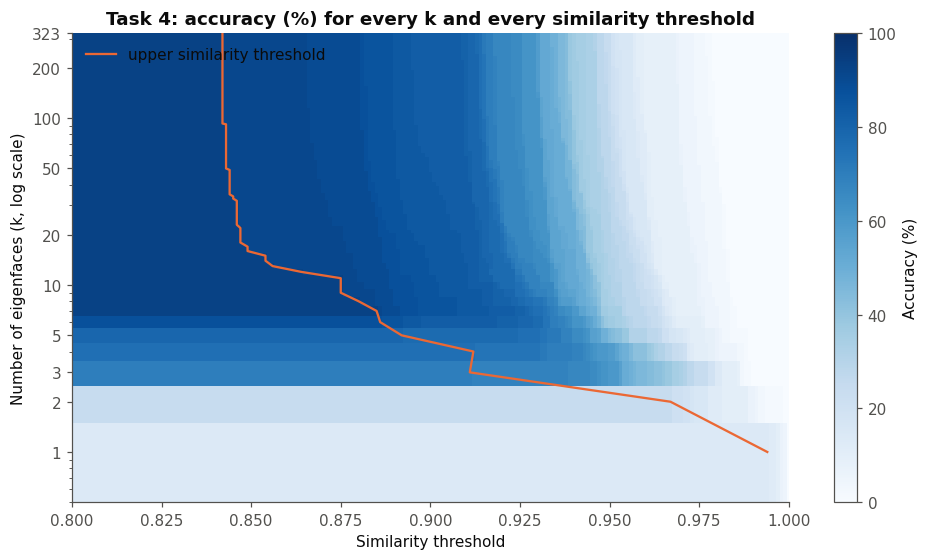

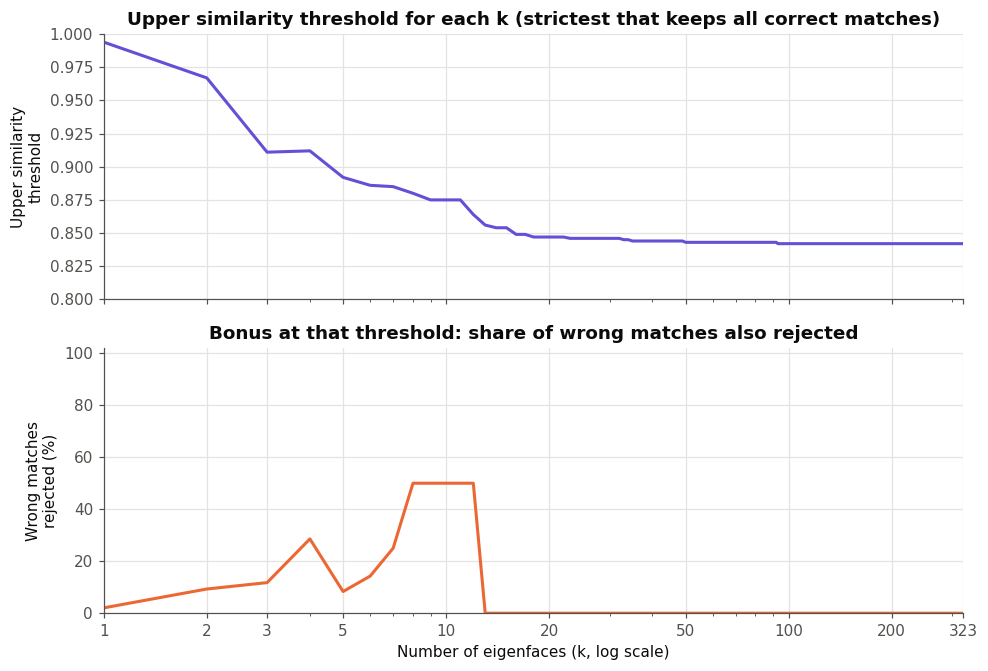

    k | accuracy | upper similarity threshold | wrong matches rejected
    1 |   14.0 % |          0.994             |   1 of 49
    2 |   24.6 % |          0.967             |   4 of 43
    3 |   70.2 % |          0.911             |   2 of 17
    5 |   78.9 % |          0.892             |   1 of 12
    7 |   93.0 % |          0.885             |   1 of 4
   10 |   93.0 % |          0.875             |   2 of 4
   15 |   93.0 % |          0.854             |   0 of 4
   20 |   93.0 % |          0.847             |   0 of 4
   30 |   93.0 % |          0.846             |   0 of 4
   50 |   93.0 % |          0.843             |   0 of 4
  100 |   93.0 % |          0.842             |   0 of 4
  200 |   93.0 % |          0.842             |   0 of 4
  323 |   93.0 % |          0.842             |   0 of 4


In [10]:
fig, ax = plt.subplots(figsize=(9, 5.2))
cols = thresholds >= X_LO
im = ax.pcolormesh(thresholds[cols], ks, acc_thr[:, cols], cmap="Blues", vmin=0, vmax=100, shading="nearest")
ax.plot(upper_thr, ks, color=ORANGE, lw=1.5, label="upper similarity threshold")
ax.set_yscale("log")                      # log scale so small k (where things change) is visible
ax.set_yticks([1, 2, 3, 5, 10, 20, 50, 100, 200, n_eig]); ax.set_yticklabels([1, 2, 3, 5, 10, 20, 50, 100, 200, n_eig])
ax.set_xlim(X_LO, 1)
ax.set_xlabel("Similarity threshold"); ax.set_ylabel("Number of eigenfaces (k, log scale)")
ax.set_title("Task 4: accuracy (%) for every k and every similarity threshold")
ax.grid(False); ax.legend(loc="upper left")
fig.colorbar(im, ax=ax, label="Accuracy (%)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
axes[0].plot(ks, upper_thr, color=VIOLET)
axes[0].set_ylabel("Upper similarity\nthreshold"); axes[0].set_ylim(X_LO, 1)
axes[0].set_title("Upper similarity threshold for each k (strictest that keeps all correct matches)")
pct_rej = np.where(n_wrong > 0, 100 * wrong_rejected / np.maximum(n_wrong, 1), np.nan)
axes[1].plot(ks, pct_rej, color=ORANGE)
axes[1].set_ylabel("Wrong matches\nrejected (%)"); axes[1].set_ylim(0, 102)
axes[1].set_title("Bonus at that threshold: share of wrong matches also rejected")
axes[1].set_xscale("log"); axes[1].set_xlim(1, n_eig)
axes[1].set_xticks([1, 2, 3, 5, 10, 20, 50, 100, 200, n_eig]); axes[1].set_xticklabels([1, 2, 3, 5, 10, 20, 50, 100, 200, n_eig])
axes[1].set_xlabel("Number of eigenfaces (k, log scale)")
plt.tight_layout(); plt.show()

print(f"{'k':>5} | accuracy | upper similarity threshold | wrong matches rejected")
for k in [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100, 200, n_eig]:
    print(f"{k:>5} | {accuracy[k-1]:6.1f} % | {upper_thr[k-1]:>14.3f}             | "
          f"{wrong_rejected[k-1]:>3} of {n_wrong[k-1]}")

## 7. (Optional) Is the result just luck of the split?
The 85/15 split is random. To check the findings are not a fluke, this repeats task 3 with 20 different random splits
and shows the average accuracy (line) and the lowest/highest (shaded band).

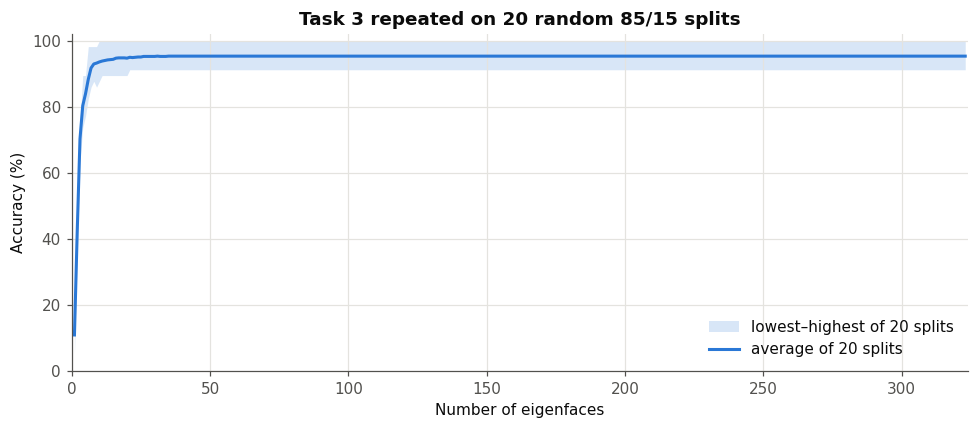

k =   1: average  11.0 %   (range 5.3 – 17.5 %)
k =   3: average  70.3 %   (range 63.2 – 75.4 %)
k =   5: average  83.9 %   (range 77.2 – 89.5 %)
k =  10: average  93.6 %   (range 87.7 – 100.0 %)
k =  15: average  94.4 %   (range 89.5 – 100.0 %)
k =  20: average  94.7 %   (range 89.5 – 100.0 %)
k =  30: average  95.3 %   (range 91.2 – 100.0 %)
k =  50: average  95.4 %   (range 91.2 – 100.0 %)
k = 100: average  95.4 %   (range 91.2 – 100.0 %)
k = 323: average  95.4 %   (range 91.2 – 100.0 %)


In [11]:
def accuracy_curve(train_idx, test_idx):
    # Same steps as sections 4 and 5, packed into one function
    Tr, Te = X[:, train_idx], X[:, test_idx]
    a = Tr.mean(axis=1, keepdims=True)
    A, B = Tr - a, Te - a
    if MATLAB_UINT8_QUIRKS:
        a = np.round(a); A, B = np.clip(Tr - a, 0, 255), np.clip(Te - a, 0, 255)
    U_, _, _ = np.linalg.svd(A.T @ A)
    EF = A @ U_
    Ftr, Fte = A.T @ EF, B.T @ EF
    if MATLAB_UINT8_QUIRKS:
        Ftr, Fte = to_uint8(Ftr), to_uint8(Fte)
    d = np.cumsum((Fte[:, None, :] - Ftr[None, :, :]) ** 2, axis=2)
    return 100 * (labels[train_idx][d.argmin(axis=1)] == labels[test_idx][:, None]).mean(axis=0)

curves = np.array([accuracy_curve(*split_85_15(labels, TEST_FRACTION, s)) for s in range(20)])
mean_c = curves.mean(axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(ks, curves.min(axis=0), curves.max(axis=0), color=BLUE, alpha=0.18, lw=0,
                label="lowest–highest of 20 splits")
ax.plot(ks, mean_c, color=BLUE, label="average of 20 splits")
ax.set_xlabel("Number of eigenfaces"); ax.set_ylabel("Accuracy (%)")
ax.set_title("Task 3 repeated on 20 random 85/15 splits")
ax.set_xlim(0, n_eig + 1); ax.set_ylim(0, 102); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

for k in [1, 3, 5, 10, 15, 20, 30, 50, 100, n_eig]:
    print(f"k = {k:>3}: average {mean_c[k-1]:5.1f} %   (range {curves[:, k-1].min():.1f} – {curves[:, k-1].max():.1f} %)")

## 8. Conclusion

*(Numbers below are from the run with `SEED = 42`. A different seed gives a different random split, so the exact numbers move a little, but the overall pattern stays the same.)*

### What we found in Task 3: how many eigenfaces do we need?
- **Too few eigenfaces don't work.** With only 1 eigenface the system recognises just 14 % of the test faces; with 2 it's 25 %. One or two "face ingredients" are not enough to tell 38 people apart.
- **Accuracy climbs very fast.** With 3 eigenfaces it's already 70 %, with 6 it's 88 %, and with **7 eigenfaces it reaches 93 % (53 of the 57 test photos correct)**.
- **After that, adding more doesn't help.** From 7 all the way up to all 323 eigenfaces the accuracy stays flat at 93 %. The first few eigenfaces (the ones with the biggest eigenvalues) carry the information that makes faces different from each other. The later ones only describe tiny details, lighting and noise, which barely change the distances.
- **The MATLAB default of 15 eigenfaces is a good choice.** It is already on the flat "top" part of the curve (93 %), uses only 15 numbers per face instead of 10 304 pixels, and leaves some safety margin.
- **Luck of the split matters a bit.** Repeating the experiment on 20 different random 85/15 splits gives an average of about **94 % at 15 eigenfaces and 95 % from about 30 eigenfaces on**, with single runs anywhere between about 88 % and 100 %. With only 57 test photos, each photo counts for almost 2 %, so small differences between runs are normal.
- **Side note on the original MATLAB code:** it stores the "face minus average" values as `uint8`, which turns every negative value into 0. When we copy that behaviour exactly (`MATLAB_UINT8_QUIRKS = True`), accuracy at 15 eigenfaces drops to 82.5 % and it needs about 95 eigenfaces to reach its best. Doing the math with normal decimal numbers fixes this, and that is what this notebook does by default.

### What we found in Task 4: the similarity threshold
- All best-match similarity scores land between about **0.84 and 1.0**, so the interesting part of the threshold range is 0.84–1.0.
- For every number of eigenfaces, the accuracy stays at its Task 3 value while the threshold is low. Once the threshold passes a certain point, the system starts rejecting correct matches and the accuracy falls quickly. Near 0.99 almost everything is rejected.
- **The upper similarity threshold** (the strictest setting that still keeps every correct match) is about **0.885 for 7 eigenfaces, 0.875 for 10, 0.854 for 15, and settles at about 0.842 once 100 or more eigenfaces are used**. Using more eigenfaces makes the scores a little lower for everyone, so the threshold has to be a little lower too.
- **Why bother with a threshold?** Wrong matches usually have a *lower* similarity than right ones. With 7–10 eigenfaces and the threshold set at its upper value, the system rejects **1–2 of the 4 wrong matches** ("I'm not sure who this is") **without losing a single correct one**. With 15 or more eigenfaces the remaining wrong matches look just as similar as the weakest correct match, so the threshold can no longer separate them.

### In one paragraph
Eigenfaces work well on this dataset. Only a handful of the strongest eigenfaces (about 7–15) are needed to recognise roughly 93–95 % of the test faces, and using hundreds more adds nothing. A similarity threshold doesn't raise the number of faces recognised, but set just right (about **0.875 with 10 eigenfaces**) it lets the system say "unknown" for some of its mistakes without throwing away any correct answers. The best practical setting from these experiments is **about 10–15 eigenfaces with a similarity threshold of about 0.85–0.88**. Because the test set is small (57 photos) and the threshold was chosen on that same test set, real-world performance would probably be a little lower.